<a href="https://colab.research.google.com/github/Knerdy-got-moves/Floquet-Spin-1-Hamiltonian/blob/main/Hilbert_space_fragmentation_in_spin_1_floquet_Hamiltonian.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spin 1 system






## Numerically coding the system

We consider a one-dimensional spin-1 quantum system with the time-dependent Hamiltonian:
\begin{align}
H(t) &= H_1 + H_2(t)
\end{align}
where the hopping term is given by:
\begin{align}
H_1 &= J \sum_i (S_i^+ S_{i+1}^- + \text{H.c.})
\end{align}
and the time-dependent driving term is:
\begin{align}
H_2(t) &= \sum_i V(t) (S_i^z)^2
\end{align}

Here, $S_i^{\pm}$ and $S_i^z$ are the standard spin-1 operators at site $i$.
This model conserves the total number of excitations, defined as the total $S^z$ quantum number. For the periodic driving protocol, we employ a square-wave modulation:
\begin{align}
V(t) = \begin{cases}
-V_0 & \text{for } 0 < t \leq T/2 \\
+V_0 & \text{for } T/2 < t \leq T
\end{cases}
\end{align}

We work in the regime where $V_0 \gg J$, making this system amenable to Floquet perturbation theory with $H_2(t)$ as the exactly solvable part and $H_1$ as the perturbation.

In [ ]:
!pip install quspin

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.9/199.9 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 103.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.3/278.3 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 77.8 MB/s eta 0:00:00


Hilbert space dimension: 243
Hermiticity check passed!
Symmetry checks passed!
Hermiticity check passed!
Symmetry checks passed!
Enter initial spin-1 product state for L=5.
- as '012' string (0→-1, 1→0, 2→+1), e.g. 20121
- or L values in {-1,0,+1}, e.g. -1 0 +1 -1 0
- or 'alt' (even: ±1 random, odd: 0), or 'random'
State: 12102
Initial state (quspin codes): 12102
Initial state (m values):     +0 +1 +0 -1 +1
Random alternating state: 12102
Hermiticity check passed!
Symmetry checks passed!
Hermiticity check passed!
Symmetry checks passed!
Hermiticity check passed!
Symmetry checks passed!
Hermiticity check passed!
Symmetry checks passed!
Hermiticity check passed!
Symmetry checks passed!


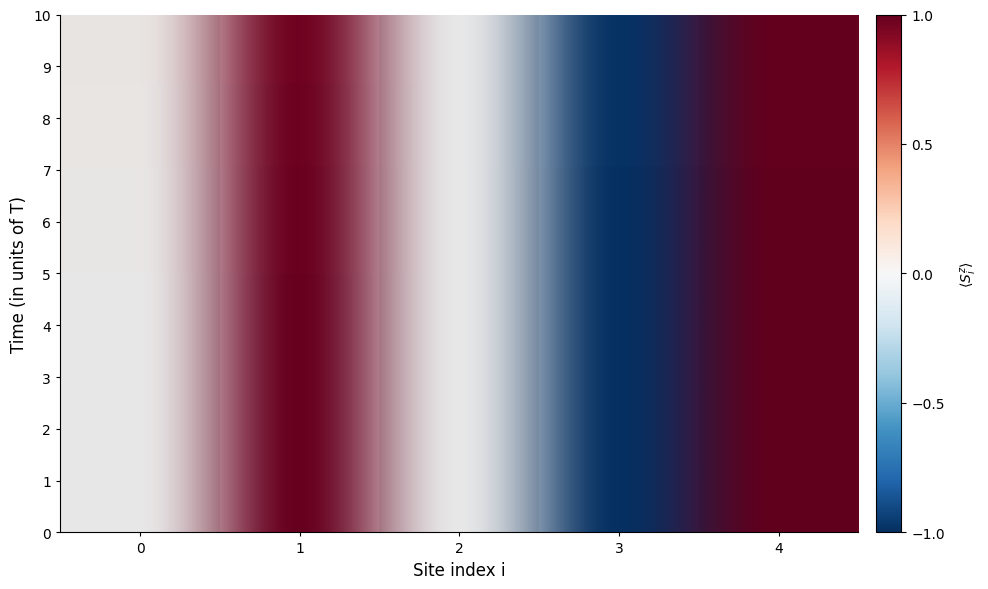

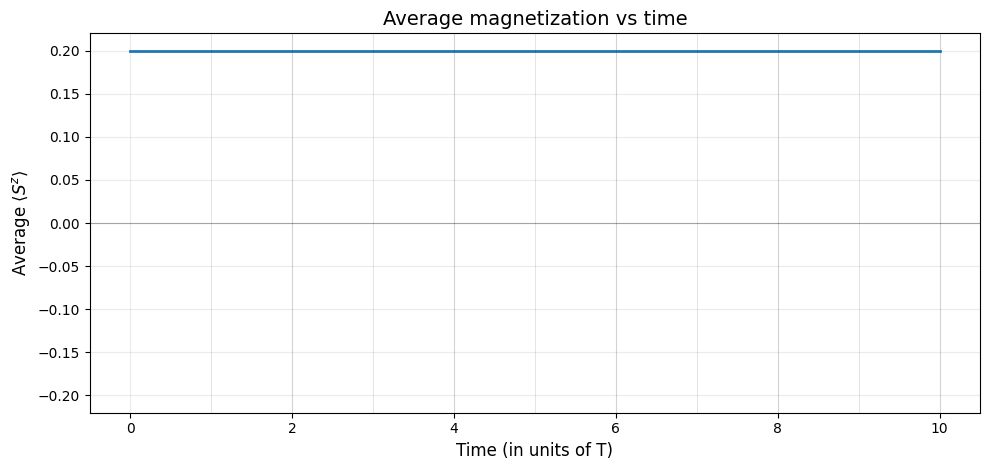

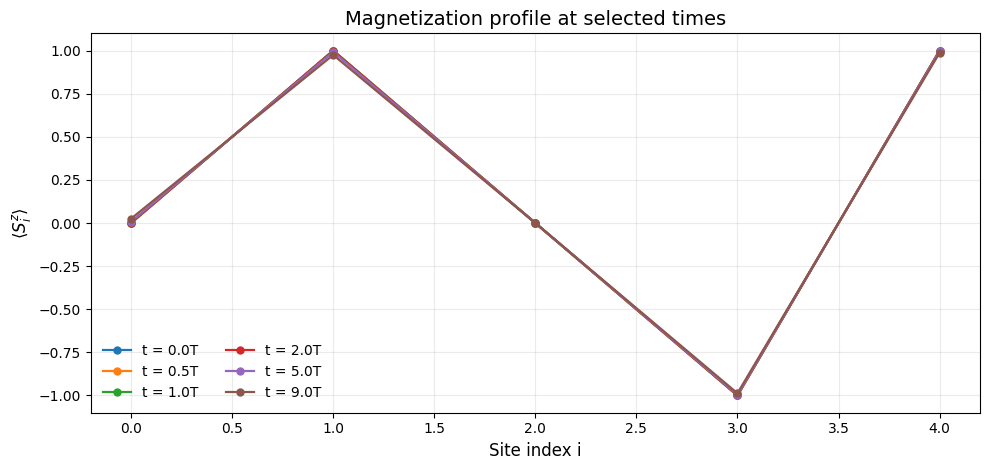


Simulation parameters:
Number of sites: 5
Hopping strength J: 1.0
Driving amplitude V0: 1000.0
Driving period T: 0.006283185307179587
V0/J ratio: 1000.0
Number of periods simulated: 10
Time step dt: 0.00012566370614359174

Initial average magnetization: 0.2000
Final average magnetization: 0.2000
Max |<S^z>|: 1.0000
Min |<S^z>|: 0.0000


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from quspin.operators import hamiltonian
from quspin.basis import spin_basis_1d
from quspin.tools.evolution import evolve  # not strictly needed, but handy
import scipy.sparse as sp
# --------------------
# System parameters
# --------------------
L = 5          # number of sites
J = 1.0         # hopping strength
V0 = 1000.0 * J   # driving amplitude (V0 >> J)
T_period = 2.0*np.pi  / V0  # driving period to freezing: 2.0*np.pi  / V0

# --------------------
# Time parameters
# --------------------
n_periods = 10
dt = T_period / 50
times = np.arange(0.0, n_periods * T_period + 1e-12, dt)  # tiny eps to include endpoint
n_times = len(times)

# --------------------
# Basis (spin-1 chain)
# --------------------
basis = spin_basis_1d(L, S="1", pauli=0)  # S^a operators (not Pauli matrices)
print(f"Hilbert space dimension: {basis.Ns}")

# --------------------
# Operators
# --------------------
# H1 = J * sum_i (S^+_i S^-_{i+1} + S^-_i S^+_{i+1}) with PBC
hop_coupling = [
    ["+-", [[J, i, (i+1) % L] for i in range(L)]],
    ["-+", [[J, i, (i+1) % L] for i in range(L)]],
]
H1 = hamiltonian(hop_coupling, [], basis=basis, dtype=np.complex128)

# H2(t) = V(t) * sum_i (S^z_i)^2
# For spin-1, (S^z)^2 has eigenvalues 1 on |±1> and 0 on |0>.
# QuSpin allows onsite "zz" with same site twice: [i, i].
onsite_zz = [[1.0, i, i] for i in range(L)]
# --- replace the square_wave and dynamic_list parts ---

# driving function must be f(t, *args) with positional args
def square_wave(t, T, amp):
    t_mod = t % T
    return (-amp) if (t_mod <= T/2.0) else (amp)

dynamic_list = [
    ["zz", onsite_zz, square_wave, [T_period, V0]],  # args as a list, not dict
]

H = hamiltonian(hop_coupling, dynamic_list, basis=basis, dtype=np.complex128)

# Initial product state: alternating |+1> or |-1> and |0>
# spin-1 string code: "0"->m=-1, "1"->m=0, "2"->m=+1
# --------------------
# --------------------
# Initial product state: ask the user
# spin-1 string code: "0"->m=-1, "1"->m=0, "2"->m=+1
# --------------------
rng = np.random.default_rng(seed=123)

def build_alt_state(L, rng):
    s = []
    for i in range(L):
        if i % 2 == 0:
            s.append(rng.choice(["0", "2"]))  # ±1
        else:
            s.append("1")                      # 0
    return "".join(s)

def parse_user_state(text, L):
    t = text.strip().lower()

    if t == "alt":
        return build_alt_state(L, rng)

    if t == "random":
        # fully random per site in {-1,0,+1}
        map_code = {"-1": "0", "0": "1", "+1": "2"}
        s = "".join(map_code[str(rng.choice([-1, 0, +1]))] for _ in range(L))
        return s

    # case A: raw quspin string like "20120"
    if set(t) <= set("012") and len(t) == L:
        return t

    # case B: space/comma separated m values like "-1 0 +1 -1 0"
    tokens = t.replace(",", " ").split()
    if len(tokens) == L:
        mapped = []
        for tok in tokens:
            tok = tok.strip().replace("＋", "+").replace("−", "-")  # handle unicode signs
            if tok in {"-1", "-"}:
                mapped.append("0")
            elif tok in {"0"}:
                mapped.append("1")
            elif tok in {"+1", "+", "1"}:
                mapped.append("2")
            else:
                raise ValueError(f"invalid spin value '{tok}', use -1, 0, or +1")
        return "".join(mapped)

    raise ValueError("could not parse the state; provide a length-L '012' string or L spins in {-1,0,+1}")

# prompt the user
prompt = (
    f"Enter initial spin-1 product state for L={L}.\n"
    f"- as '012' string (0→-1, 1→0, 2→+1), e.g. 20121\n"
    f"- or L values in {{-1,0,+1}}, e.g. -1 0 +1 -1 0\n"
    f"- or 'alt' (even: ±1 random, odd: 0), or 'random'\n"
    f"State: "
)

try:
    user_text = input(prompt)
    state_str = parse_user_state(user_text, L)
except Exception as e:
    print(f"[warning] {e}. using fallback 'alt' pattern.")
    state_str = build_alt_state(L, rng)

# build |psi0>
psi0 = np.zeros(basis.Ns, dtype=np.complex128)
psi0[basis.index(state_str)] = 1.0

# pretty print chosen state in both codes
code_to_m = {"0": -1, "1": 0, "2": +1}
m_list = [code_to_m[c] for c in state_str]
print(f"Initial state (quspin codes): {state_str}")
print(f"Initial state (m values):     {' '.join(f'{m:+d}' for m in m_list)}")


print(f"Random alternating state: {state_str}")

# --------------------
# Measurement operators: S^z_i
# --------------------
Sz_ops = [hamiltonian([["z", [[1.0, i]]]], [], basis=basis, dtype=np.complex128) for i in range(L)]

# --------------------
# Full time evolution with dynamic Hamiltonian
# H.evolve supports an array of times for time-dependent H.
# It returns states at each time in 'times'.
# --------------------
psi_t = H.evolve(psi0, 0.0, times)  # shape (n_times, Ns)

# --------------------
# Expectations
# --------------------
Sz_expect = np.zeros((L, n_times))
for t_idx, psi in enumerate(H.evolve(psi0, 0.0, times, iterate=True)):
    for i in range(L):
        Sz_expect[i, t_idx] = np.real(Sz_ops[i].expt_value(psi))


# --------------------
# Plots (refined: use imshow heatmap)
# --------------------
i# --- Space–time heatmap styled like your image ---
from matplotlib.colors import TwoSlopeNorm

tT = times / T_period

fig, ax = plt.subplots(figsize=(10, 6))

# alternating column shading for readability
for col in range(L):
    if col % 2 == 0:
        ax.axvspan(col-0.5, col+0.5, color='k', alpha=0.06, lw=0)

im = ax.imshow(
    Sz_expect.T,
    origin='lower',
    aspect='auto',
    extent=[-0.5, L-0.5, tT[0], tT[-1]],
    cmap='RdBu_r',
    norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
)

# axes look
ax.set_facecolor('white')
ax.set_xticks(np.arange(L))
ax.set_xlabel('Site index i', fontsize=12)
ax.set_ylabel('Time (in units of T)', fontsize=12)
ax.tick_params(axis='both', which='both', length=3, width=0.8)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# tidy period ticks on y
ax.set_yticks(np.arange(0, n_periods+1, 1))

# slim colorbar on the right
cbar = fig.colorbar(im, ax=ax, pad=0.02, fraction=0.05)
cbar.set_label(r'$\langle S^z_i \rangle$', rotation=90, labelpad=10)
cbar.set_ticks([-1, -0.5, 0, 0.5, 1])
cbar.outline.set_linewidth(0.8)

fig.tight_layout()
plt.show()


# 2) Average magnetization vs time (no offset notation)
fig, ax = plt.subplots(figsize=(10, 4.8))
avg_Sz = np.mean(Sz_expect, axis=0)
ax.plot(tT, avg_Sz, lw=2)

ax.set_xlabel('Time (in units of T)', fontsize=12)
ax.set_ylabel(r'Average $\langle S^z \rangle$', fontsize=12)
ax.set_title('Average magnetization vs time', fontsize=14)

# turn off offset like "1e-1 + …"
ax.ticklabel_format(useOffset=False, style='plain', axis='y')

# show zero line
ax.axhline(0, color='k', lw=0.8, alpha=0.3)

# faint vertical guides at periods
for k in range(1, n_periods + 1):
    ax.axvline(x=k, color='k', lw=0.5, alpha=0.15)

# auto scale but avoid huge symmetric limits if nearly flat:
span = np.max(np.abs(avg_Sz))
if span < 1e-3:
    ax.set_ylim(-1.5e-3, 1.5e-3)
else:
    ax.set_ylim(-1.1*span, 1.1*span)

ax.grid(alpha=0.25)
fig.tight_layout()

# 3) Magnetization profile snapshots
fig, ax = plt.subplots(figsize=(10, 4.8))
time_snapshots = [0, T_period/2, T_period, 2*T_period, 5*T_period, 9*T_period]

for t_snap in time_snapshots:
    t_idx = int(round(t_snap / dt))
    if 0 <= t_idx < n_times:
        ax.plot(range(L), Sz_expect[:, t_idx], 'o-', lw=1.6, ms=5,
                label=f't = {t_snap/T_period:.1f}T')

ax.set_xlabel('Site index i', fontsize=12)
ax.set_ylabel(r'$\langle S^z_i \rangle$', fontsize=12)
ax.set_title('Magnetization profile at selected times', fontsize=14)
ax.set_ylim(-1.1, 1.1)
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=2)
fig.tight_layout()

plt.show()


# --------------------
# Diagnostics
# --------------------
print("\nSimulation parameters:")
print(f"Number of sites: {L}")
print(f"Hopping strength J: {J}")
print(f"Driving amplitude V0: {V0}")
print(f"Driving period T: {T_period}")
print(f"V0/J ratio: {V0/J}")
print(f"Number of periods simulated: {n_periods}")
print(f"Time step dt: {dt}")
print(f"\nInitial average magnetization: {np.mean(Sz_expect[:, 0]):.4f}")
print(f"Final average magnetization: {np.mean(Sz_expect[:, -1]):.4f}")
print(f"Max |<S^z>|: {np.max(np.abs(Sz_expect)):.4f}")
print(f"Min |<S^z>|: {np.min(np.abs(Sz_expect)):.4f}")


##Dimension of the fragments in the Hilbert space given that the number of +1 spins is conserved and the number of -1 spins is conserved.

# Floquet Hamiltonian

\begin{align*}
H_F^{(1)} &= \frac{i\hbar}{T} U_1^{(1)}(T,0) = \frac{i\hbar}{T} (T_1 + T_2) \\
&= \sum_{i}\left[\delta_{X_{nm}, 0} + (1-\delta_{X_{nm}, 0}) \frac{\sin(V_0 T X_{nm}/(2\hbar))}{V_0 T X_{nm}/(2\hbar)} e^{i V_0 T X_{nm}/(2\hbar)} \right] (S_i^+ S_{i+1}^- + H.C.),
\end{align*} where, the interaction term is: \begin{align*}
        H_1 &= J \sum_i (S_i^+ S_{i+1}^- + H.C.)
    \end{align*}
and the local operator is defined as :
\begin{align}
\hat{X}_i = \left[\frac{1}{2} - (S_i^z)^2\right] + \left[\frac{1}{2} - (S_{i+1}^z)^2\right]
\end{align}


In [ ]:
# Fragmentation finder for a spin-1 chain with N_+ and N_- conserved
# Requires: quspin, numpy, scipy
# Mapping of local symbols:
#   "0" -> m = -1
#   "1" -> m =  0
#   "2" -> m = +1

import itertools as it
import numpy as np
from collections import defaultdict
from quspin.basis import spin_basis_1d
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from math import comb

# ----------------------------
# user parameters
# ----------------------------
L = 8                 # number of sites
PBC = False           # periodic boundary conditions for the move set
N_plus = 2            # desired number of +1 (m=+1) spins
N_minus = 3           # desired number of -1 (m=-1) spins

# Choose the kinetic rules (your Floquet "gates"):
#   "vacancy_assisted": only swap a 0 with a ±1 on a bond (no ±1-±1 swaps)  -> often fragments
#   "all_swaps":        swap any two different local states on a bond        -> usually one component
move_rule = "vacancy_assisted"

# ----------------------------
# helpers
# ----------------------------

def enumerate_sector_strings(L, N_plus, N_minus):
    """Return all length-L strings over {'0','1','2'} with #('2')=N_plus and #('0')=N_minus."""
    if N_plus + N_minus > L:
        return []
    N_zero = L - (N_plus + N_minus)
    # positions of 2's:
    sector = []
    for pos_plus in it.combinations(range(L), N_plus):
        remaining = [i for i in range(L) if i not in pos_plus]
        for pos_minus in it.combinations(remaining, N_minus):
            s = ['1'] * L  # start with zeros (m=0)
            for i in pos_plus:
                s[i] = '2'  # m=+1
            for j in pos_minus:
                s[j] = '0'  # m=-1
            sector.append(''.join(s))
    return sector

def neighbors_from_rule(state_str, PBC=True, rule="vacancy_assisted"):
    """Generate all neighbor strings connected by one allowed nearest-neighbor move."""
    L = len(state_str)
    s = list(state_str)
    bonds = [(i, (i+1) % L) for i in range(L)] if PBC else [(i, i+1) for i in range(L-1)]
    nbrs = []
    for i, j in bonds:
        a, b = s[i], s[j]
        if rule == "vacancy_assisted":
            # swap only if exactly one is '1' and the other is '0' or '2'
            cond = (a == '1' and b in ('0','2')) or (b == '1' and a in ('0','2'))
        elif rule == "all_swaps":
            cond = (a != b)
        else:
            raise ValueError("unknown rule")
        if cond:
            t = s.copy()
            t[i], t[j] = t[j], t[i]
            nbrs.append(''.join(t))
    return nbrs

def build_fragmentation(sector_strings, rule="vacancy_assisted", PBC=True):
    """Return labels and sizes of connected components for the given sector."""
    n = len(sector_strings)
    if n == 0:
        return np.array([], dtype=int), np.array([], dtype=int), {}

    # map string <-> local index within sector
    str_to_local = {st: k for k, st in enumerate(sector_strings)}

    rows, cols = [], []
    for k, st in enumerate(sector_strings):
        for nb in neighbors_from_rule(st, PBC=PBC, rule=rule):
            if nb in str_to_local:
                j = str_to_local[nb]
                if j != k:
                    rows.append(k); cols.append(j)

    # undirected, unweighted adjacency
    data = np.ones(len(rows), dtype=np.int8)
    A = sp.coo_matrix((data, (rows, cols)), shape=(n, n))
    A = (A + A.T).tocsr()
    A.eliminate_zeros()

    n_comp, labels = connected_components(A, directed=False, return_labels=True)
    sizes = np.bincount(labels, minlength=n_comp)
    return labels, sizes, str_to_local

def sector_dimension_closed_form(L, N_plus, N_minus):
    """Multinomial dimension of the (N_+, N_-) sector."""
    N_zero = L - (N_plus + N_minus)
    if N_zero < 0:
        return 0
    return comb(L, N_plus) * comb(L - N_plus, N_minus)

# ----------------------------
# main: compute fragments for a chosen sector
# ----------------------------
basis = spin_basis_1d(L, S="1", pauli=False)  # used for consistency with your workflow

sector_strings = enumerate_sector_strings(L, N_plus, N_minus)
labels, sizes, str_to_local = build_fragmentation(sector_strings, rule=move_rule, PBC=PBC)

print(f"L={L}, PBC={PBC}, rule={move_rule}")
print(f"sector (N_+,N_-) = ({N_plus},{N_minus})")
print(f"sector size (combinatorial) = {sector_dimension_closed_form(L, N_plus, N_minus)}")
print(f"sector size (enumerated)    = {len(sector_strings)}")
print(f"number of fragments         = {len(sizes)}")
print("fragment sizes (sorted)     =", np.sort(sizes)[::-1])

# optional: list one representative state per fragment
reps = {}
for st, k in str_to_local.items():
    lab = labels[k]
    if lab not in reps:
        reps[lab] = st
print("\nrepresentatives (one per fragment):")
for lab, st in sorted(reps.items()):
    print(f"  fragment {lab:3d}: {st}")

# ----------------------------
# optional: sweep all sectors and summarize
# ----------------------------
def sweep_all_sectors(L, rule="vacancy_assisted", PBC=True):
    out = []
    for Np in range(L+1):
        for Nm in range(L+1-Np):
            sec = enumerate_sector_strings(L, Np, Nm)
            if not sec:
                continue
            _, sizes, _ = build_fragmentation(sec, rule=rule, PBC=PBC)
            # convert np.int64 -> int and print ALL sizes (sorted, largest first)
            sizes_sorted = sorted((int(x) for x in sizes), reverse=True)
            out.append(((Np, Nm), len(sec), len(sizes_sorted), sizes_sorted))
    return out

# Example sweep (comment out if L is large)
summary = sweep_all_sectors(L=L, rule=move_rule, PBC=PBC)

print("\nsector summary: (N_+,N_-), sector_dim, #fragments, fragment sizes")
for (Np, Nm), dim, nf, sizes_all in summary:
    print(f"  ({Np:2d},{Nm:2d})  {dim:6d}   {nf:4d}   {sizes_all}")


L=8, PBC=False, rule=vacancy_assisted
sector (N_+,N_-) = (2,3)
sector size (combinatorial) = 560
sector size (enumerated)    = 560
number of fragments         = 10
fragment sizes (sorted)     = [56 56 56 56 56 56 56 56 56 56]

representatives (one per fragment):
  fragment   0: 22000111
  fragment   1: 20200111
  fragment   2: 20020111
  fragment   3: 20002111
  fragment   4: 02200111
  fragment   5: 02020111
  fragment   6: 02002111
  fragment   7: 00220111
  fragment   8: 00202111
  fragment   9: 00022111

sector summary: (N_+,N_-), sector_dim, #fragments, fragment sizes
  ( 0, 0)       1      1   [1]
  ( 0, 1)       8      1   [8]
  ( 0, 2)      28      1   [28]
  ( 0, 3)      56      1   [56]
  ( 0, 4)      70      1   [70]
  ( 0, 5)      56      1   [56]
  ( 0, 6)      28      1   [28]
  ( 0, 7)       8      1   [8]
  ( 0, 8)       1      1   [1]
  ( 1, 0)       8      1   [8]
  ( 1, 1)      56      2   [28, 28]
  ( 1, 2)     168      3   [56, 56, 56]
  ( 1, 3)     280      4   [7